In [1]:
import geopandas as gpd
import mapclassify
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [4]:
from pathlib import Path

In [5]:
data_folder = Path(
    "/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data"
)

boundaries_folder = data_folder / "limiti"
terrain_folder = data_folder / "orografia"

In [6]:
print("Boundary shapefiles:")
for file_path in sorted(boundaries_folder.rglob("*.shp")):
    print(file_path)

Boundary shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/limiti/Com01012026/Com01012026_WGS84.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/limiti/ProvCM01012026/ProvCM01012026_WGS84.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/limiti/Reg01012026/Reg01012026_WGS84.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/limiti/RipGeo01012026/RipGeo01012026_WGS84.shp


In [7]:
print("\nTerrain shapefiles:")
for file_path in sorted(terrain_folder.rglob("*.shp")):
    print(file_path)


Terrain shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte1.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte2.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/orografia/CTR_H_Orografia_1_S.shp


In [9]:
boundaries_path = "/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/limiti/Com01012026/Com01012026_WGS84.shp"

municipalities = gpd.read_file(boundaries_path)

municipalities.head()

,COD_RIP,COD_REG,COD_PROV,COD_CM,COD_UTS,PRO_COM,PRO_COM_T,COMUNE,COMUNE_A,CC_UTS,Shape_Leng,Shape_Area,geometry
0,1,1,1,201,201,1001,001001,AgliÃ¨,NaN,0,18035.254001,1.314626e+07,"POLYGON ((404703.561 5026682.656, 404733.562 5..."
1,1,1,1,201,201,1002,001002,Airasca,NaN,0,18408.906988,1.573931e+07,"POLYGON ((380700.909 4977305.52, 380702.627 49..."
2,1,1,1,201,201,1003,001003,Ala di Stura,NaN,0,31834.156081,4.633156e+07,"POLYGON ((364710.856 5022090.677, 364725.872 5..."
3,1,1,1,201,201,1004,001004,Albiano d'Ivrea,NaN,0,18927.262827,1.173969e+07,"POLYGON ((415942.51 5033304.612, 415962.885 50..."
4,1,1,1,201,201,1006,001006,Almese,NaN,0,17057.413964,1.787412e+07,"POLYGON ((376934.55 4999073.855, 376941.551 49..."


In [10]:
print("Rows and columns:", municipalities.shape)
print("Coordinate reference system:", municipalities.crs)
print("Column names:", municipalities.columns.tolist())

Rows and columns: (7896, 13)
Coordinate reference system: EPSG:32632
Column names: ['COD_RIP', 'COD_REG', 'COD_PROV', 'COD_CM', 'COD_UTS', 'PRO_COM', 'PRO_COM_T', 'COMUNE', 'COMUNE_A', 'CC_UTS', 'Shape_Leng', 'Shape_Area', 'geometry']


In [12]:
pantelleria = municipalities[
    municipalities["COMUNE"].str.strip().str.casefold() == "pantelleria"
].copy()

print("Selected features:", len(pantelleria))

pantelleria.head()

Selected features: 1


,COD_RIP,COD_REG,COD_PROV,COD_CM,COD_UTS,PRO_COM,PRO_COM_T,COMUNE,COMUNE_A,CC_UTS,Shape_Leng,Shape_Area,geometry
6531,5,19,81,0,81,81014,081014,Pantelleria,NaN,0,59727.703056,8.424898e+07,"MULTIPOLYGON (((772569.225 4072227.947, 772555..."


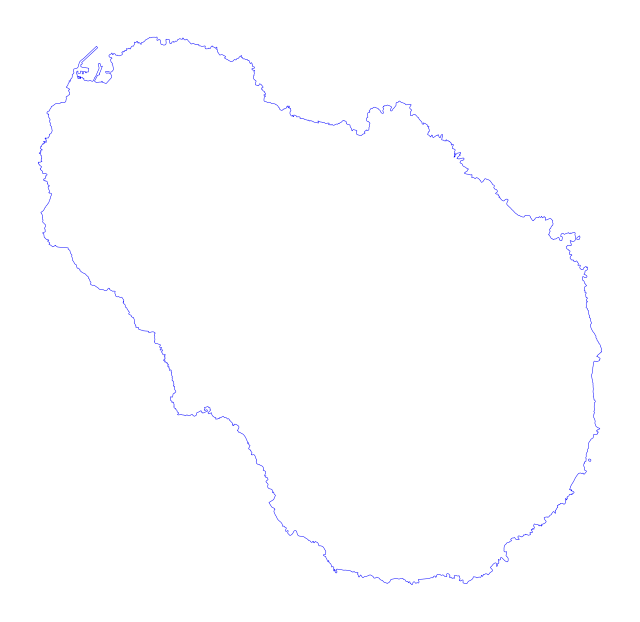

In [16]:
fig, ax = plt.subplots(figsize=(8, 8))

pantelleria.plot(
    ax=ax,
    facecolor="#ffffff",
    edgecolor="#0000ff",
    linewidth=0.35,
)

ax.set_axis_off()

plt.show()

In [17]:
terrain_folder = data_folder / "orografia"
terrain_files = sorted(terrain_folder.rglob("*.shp"))

print("Available terrain shapefiles:")
for file_path in terrain_files:
    print(file_path)

Available terrain shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte1.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte2.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/orografia/CTR_H_Orografia_1_S.shp


In [18]:
import pyogrio

for file_path in terrain_files:
    info = pyogrio.read_info(file_path)

    print("\nFile:", file_path.name)
    print("Coordinate system:", info["crs"])
    print("Geometry type:", info["geometry_type"])
    print("Fields:", info["fields"].tolist())


File: CTR_H_Orografia_1_L_parte1.shp
Coordinate system: EPSG:25833
Geometry type: LineString Z
Fields: ['OBJECTID', 'id', 'foglio', 'codice', 'descrizion', 'tipo', 'punti', 'ident', 'bordo', 'annorilev', 'flagstato', 'quota', 'st_length_', 'Shape_Leng']

File: CTR_H_Orografia_1_L_parte2.shp
Coordinate system: EPSG:25833
Geometry type: LineString Z
Fields: ['OBJECTID', 'id', 'foglio', 'codice', 'descrizion', 'tipo', 'punti', 'ident', 'bordo', 'annorilev', 'flagstato', 'quota', 'st_length_', 'Shape_Leng']

File: CTR_H_Orografia_1_S.shp
Coordinate system: EPSG:25833
Geometry type: Point Z
Fields: ['ID', 'FOGLIO', 'CODICE', 'DESCRIZION', 'TIPO', 'PROGRESSIV', 'PARZIALE', 'NUMCARATT', 'ANGOLOEST', 'ANGOLONORD', 'ALTEZ_SCAL', 'NUMERSPAZI', 'EST', 'NORD', 'QUOTA', 'TESTO', 'ANNORILEV', 'FLAGSTATO']


In [19]:
pantelleria = pantelleria.to_crs("EPSG:25833")

island_bounds = tuple(pantelleria.total_bounds)

print("Coordinate system:", pantelleria.crs)
print("Island bounds:", island_bounds)

Coordinate system: EPSG:25833
Island bounds: (np.float64(225759.69814973173), np.float64(4069526.423915387), np.float64(237325.53551278415), np.float64(4081389.0363300173))


In [21]:
terrain_folder = data_folder / "orografia"

line_files = sorted(terrain_folder.rglob("CTR_H_Orografia_1_L_parte*.shp"))

if len(line_files) != 2:
    raise ValueError(f"Expected two terrain line files, found {len(line_files)}.")

island_bounds = tuple(pantelleria.to_crs("EPSG:25833").total_bounds)

terrain_parts = [
    gpd.read_file(file_path, bbox=island_bounds) for file_path in line_files
]

terrain = gpd.GeoDataFrame(
    pd.concat(terrain_parts, ignore_index=True),
    geometry="geometry",
    crs="EPSG:25833",
)

print("Terrain features loaded:", len(terrain))

terrain[["codice", "descrizion"]].drop_duplicates()

Terrain features loaded: 748


,codice,descrizion
0,H002,Curva di livello ordinaria
1,H006,Curva ausiliaria
9,H001,Curva di livello direttrice


In [22]:
codes = terrain["codice"].astype(str).str.strip().str.upper()

contours = terrain[codes.isin(["H001", "H002"])].copy()
contours["quota"] = pd.to_numeric(contours["quota"], errors="coerce")
contours = contours.dropna(subset=["quota"])

if contours.empty:
    raise ValueError(
        "No H001/H002 contours found. Check the codice and descrizion values."
    )

print("Contour features:", len(contours))
print("Lowest contour:", contours["quota"].min(), "m")
print("Highest contour:", contours["quota"].max(), "m")

Contour features: 632
Lowest contour: 10.0 m
Highest contour: 41035.0 m


In [23]:
contours = gpd.clip(contours, pantelleria, keep_geom_type=True)
contours = contours[contours.geometry.notna() & ~contours.geometry.is_empty].copy()

if contours.empty:
    raise ValueError("No contours overlap the island boundary.")

print("Contour features within Pantelleria:", len(contours))

Contour features within Pantelleria: 632


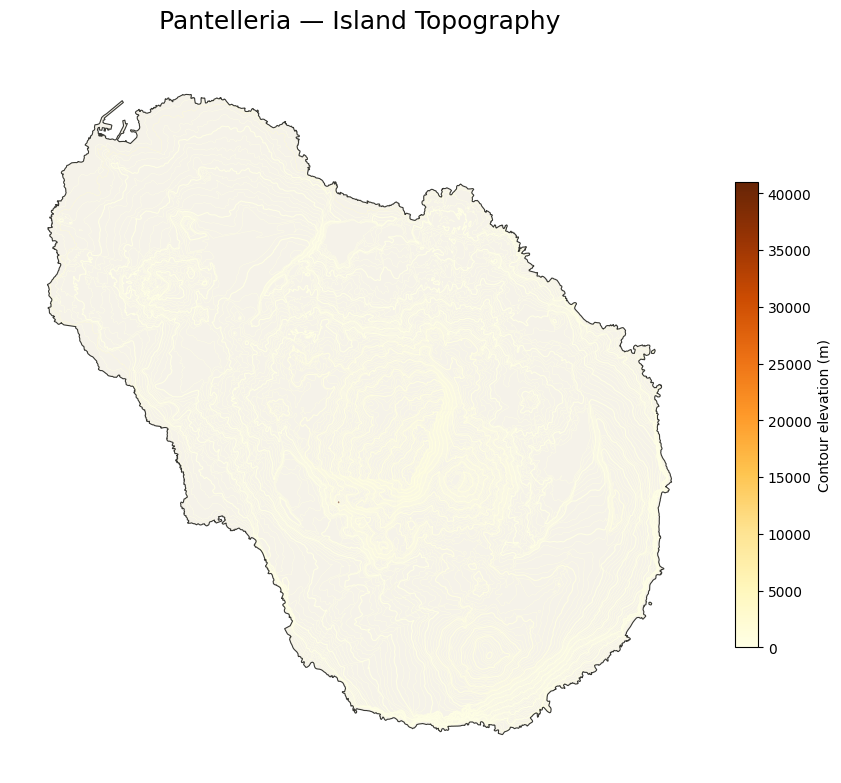

In [24]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

fig, ax = plt.subplots(figsize=(11, 11))

# Draw the island beneath the contours
pantelleria.plot(
    ax=ax,
    facecolor="#f5f2e9",
    edgecolor="none",
)

# Use the same elevation-to-colour scale for all contours
colour_map = plt.get_cmap("YlOrBr")
elevation_scale = Normalize(
    vmin=0,
    vmax=contours["quota"].max(),
)

# Emphasise major contours
major = contours["codice"].astype(str).str.strip().str.upper().eq("H001")

line_widths = major.map({True: 0.8, False: 0.3})

contours.plot(
    ax=ax,
    color=colour_map(elevation_scale(contours["quota"].to_numpy())),
    linewidth=line_widths.to_numpy(),
)

# Draw the boundary on top
pantelleria.boundary.plot(
    ax=ax,
    color="#383833",
    linewidth=0.8,
)

# Add an elevation legend
colour_bar = fig.colorbar(
    ScalarMappable(norm=elevation_scale, cmap=colour_map),
    ax=ax,
    shrink=0.55,
    pad=0.03,
)
colour_bar.set_label("Contour elevation (m)")

ax.set_title("Pantelleria — Island Topography", fontsize=18, pad=20)
ax.set_aspect("equal")
ax.set_axis_off()
ax.margins(0.06)

plt.show()

In [25]:
codes = terrain["codice"].astype(str).str.strip().str.upper()

contours = terrain[codes.isin(["H001", "H002"])].copy()

contours = gpd.clip(
    contours,
    pantelleria.to_crs(terrain.crs),
    keep_geom_type=True,
)

print("Contour lines:", len(contours))

Contour lines: 632


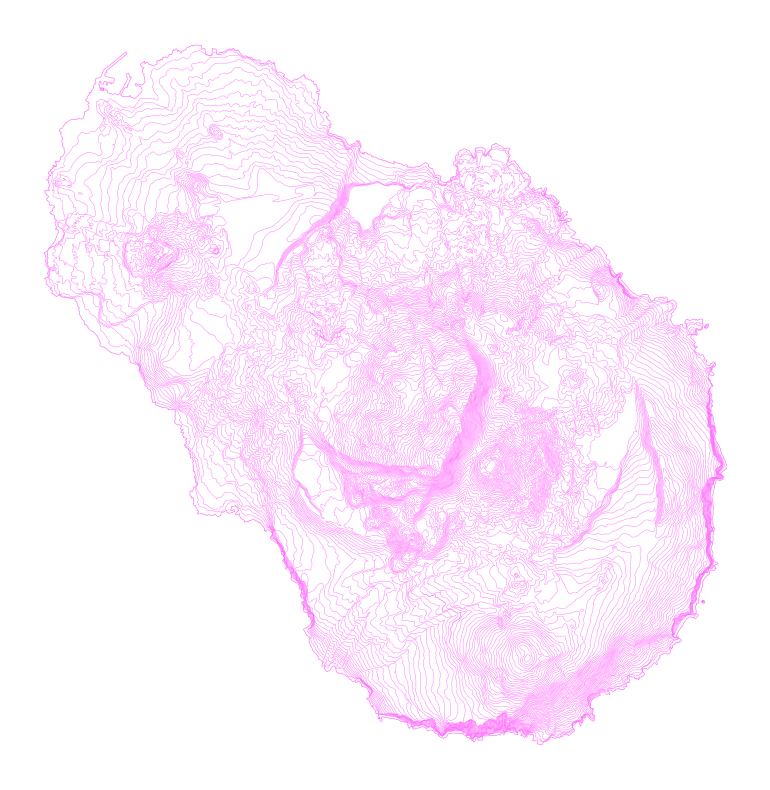

In [30]:
fig, ax = plt.subplots(figsize=(10, 10))

contours.plot(
    ax=ax,
    color="#FF6BFD",
    linewidth=0.30,
)

pantelleria.to_crs(contours.crs).boundary.plot(
    ax=ax,
    color="#FF6BFD",
    linewidth=0.45,
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.show()

In [31]:
land_use_folder = data_folder / "uso_suolo"
land_use_files = sorted(land_use_folder.rglob("*.shp"))

print("Land-use shapefiles:")
for file_path in land_use_files:
    print(file_path)

Land-use shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall/data/assignement02-data/uso_suolo/Carta_uso_suolo_Corine_Land_Cover_CLC.shp


In [32]:
import pyogrio

if not land_use_files:
    raise FileNotFoundError(f"No shapefiles found in {land_use_folder}")

for file_path in land_use_files:
    info = pyogrio.read_info(file_path)

    print("\nFile:", file_path.name)
    print("Coordinate system:", info["crs"])
    print("Geometry type:", info["geometry_type"])
    print("Fields:", info["fields"].tolist())


File: Carta_uso_suolo_Corine_Land_Cover_CLC.shp
Coordinate system: EPSG:7792
Geometry type: Polygon
Fields: ['OBJECTID', 'clc', 'nome_class']


In [35]:
land_use_parts = []

for file_path in land_use_files:
    info = pyogrio.read_info(file_path)

    # Read only polygon datasets
    if "polygon" not in info["geometry_type"].lower():
        continue

    # Match the island boundary to this dataset's coordinate system
    island_mask = pantelleria.to_crs(info["crs"])

    # Load features around Pantelleria
    part = gpd.read_file(
        file_path,
        bbox=tuple(island_mask.total_bounds),
    )

    if part.empty:
        continue

    # Trim features to the island boundary
    part = gpd.clip(part, island_mask, keep_geom_type=True)
    land_use_parts.append(part.to_crs(pantelleria.crs))

if not land_use_parts:
    raise ValueError("No land-use polygons found around Pantelleria.")

land_use = gpd.GeoDataFrame(
    pd.concat(land_use_parts, ignore_index=True),
    geometry="geometry",
    crs=pantelleria.crs,
)

print("Land-use features:", len(land_use))
print("Available fields:", land_use.columns.tolist())

land_use.head()

Land-use features: 986
Available fields: ['OBJECTID', 'clc', 'nome_class', 'geometry']


,OBJECTID,clc,nome_class,geometry
0,333185,3121,3121 Boschi a prevalenza di pini meditterranei...,"POLYGON ((234573.894 4069747.548, 234568.588 4..."
1,333214,321,321 Aree a pascolo naturale e praterie,"POLYGON ((234678.617 4070034.217, 234698.532 4..."
2,333154,3231,3231 Macchia termofila,"POLYGON ((235497.792 4071052.543, 235475.165 4..."
3,333180,3121,3121 Boschi a prevalenza di pini meditterranei...,"POLYGON ((234369.495 4070808.229, 234389.334 4..."
4,333194,321,321 Aree a pascolo naturale e praterie,"POLYGON ((234395.933 4070640.192, 234297.004 4..."


In [36]:
land_use_parts = []

for file_path in land_use_files:
    info = pyogrio.read_info(file_path)

    # Read only polygon datasets
    if "polygon" not in info["geometry_type"].lower():
        continue

    # Match the island boundary to this dataset's coordinate system
    island_mask = pantelleria.to_crs(info["crs"])

    # Load features around Pantelleria
    part = gpd.read_file(
        file_path,
        bbox=tuple(island_mask.total_bounds),
    )

    if part.empty:
        continue

    # Trim features to the island boundary
    part = gpd.clip(part, island_mask, keep_geom_type=True)
    land_use_parts.append(part.to_crs(pantelleria.crs))

if not land_use_parts:
    raise ValueError("No land-use polygons found around Pantelleria.")

land_use = gpd.GeoDataFrame(
    pd.concat(land_use_parts, ignore_index=True),
    geometry="geometry",
    crs=pantelleria.crs,
)

print("Land-use features:", len(land_use))
print("Available fields:", land_use.columns.tolist())

land_use.head()

Land-use features: 986
Available fields: ['OBJECTID', 'clc', 'nome_class', 'geometry']


,OBJECTID,clc,nome_class,geometry
0,333185,3121,3121 Boschi a prevalenza di pini meditterranei...,"POLYGON ((234573.894 4069747.548, 234568.588 4..."
1,333214,321,321 Aree a pascolo naturale e praterie,"POLYGON ((234678.617 4070034.217, 234698.532 4..."
2,333154,3231,3231 Macchia termofila,"POLYGON ((235497.792 4071052.543, 235475.165 4..."
3,333180,3121,3121 Boschi a prevalenza di pini meditterranei...,"POLYGON ((234369.495 4070808.229, 234389.334 4..."
4,333194,321,321 Aree a pascolo naturale e praterie,"POLYGON ((234395.933 4070640.192, 234297.004 4..."


In [37]:
land_use_parts = []

for file_path in land_use_files:
    info = pyogrio.read_info(file_path)

    # Read only polygon datasets
    if "polygon" not in info["geometry_type"].lower():
        continue

    # Match the island boundary to this dataset's coordinate system
    island_mask = pantelleria.to_crs(info["crs"])

    # Load features around Pantelleria
    part = gpd.read_file(
        file_path,
        bbox=tuple(island_mask.total_bounds),
    )

    if part.empty:
        continue

    # Trim features to the island boundary
    part = gpd.clip(part, island_mask, keep_geom_type=True)
    land_use_parts.append(part.to_crs(pantelleria.crs))

if not land_use_parts:
    raise ValueError("No land-use polygons found around Pantelleria.")

land_use = gpd.GeoDataFrame(
    pd.concat(land_use_parts, ignore_index=True),
    geometry="geometry",
    crs=pantelleria.crs,
)

print("Land-use features:", len(land_use))
print("Available fields:", land_use.columns.tolist())

land_use.head()

Land-use features: 986
Available fields: ['OBJECTID', 'clc', 'nome_class', 'geometry']


,OBJECTID,clc,nome_class,geometry
0,333185,3121,3121 Boschi a prevalenza di pini meditterranei...,"POLYGON ((234573.894 4069747.548, 234568.588 4..."
1,333214,321,321 Aree a pascolo naturale e praterie,"POLYGON ((234678.617 4070034.217, 234698.532 4..."
2,333154,3231,3231 Macchia termofila,"POLYGON ((235497.792 4071052.543, 235475.165 4..."
3,333180,3121,3121 Boschi a prevalenza di pini meditterranei...,"POLYGON ((234369.495 4070808.229, 234389.334 4..."
4,333194,321,321 Aree a pascolo naturale e praterie,"POLYGON ((234395.933 4070640.192, 234297.004 4..."


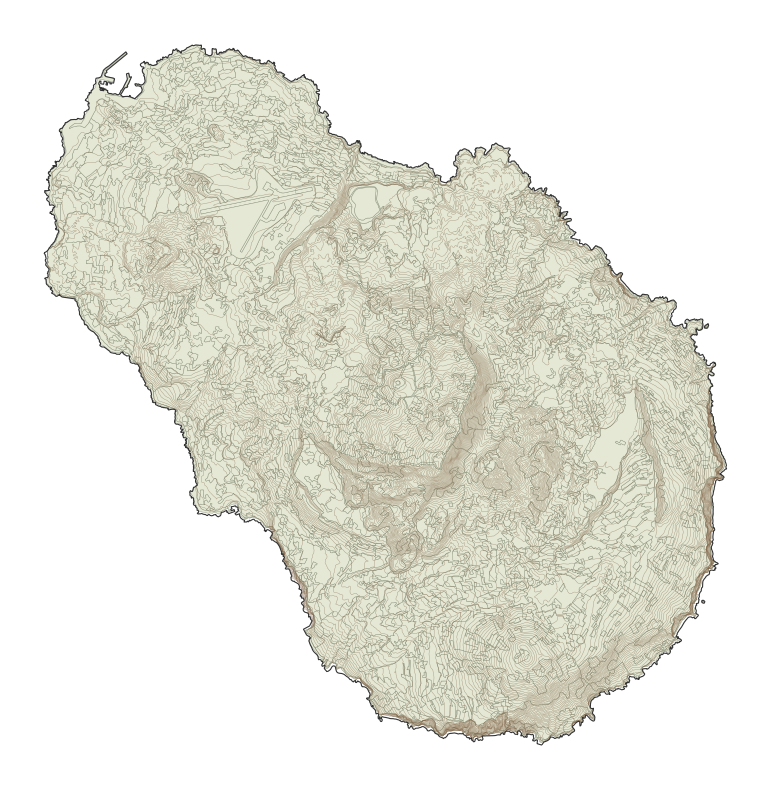

In [41]:
fig, ax = plt.subplots(figsize=(10, 10))

# Draw land-use polygons
land_use.plot(
    ax=ax,
    facecolor="#e4e8d5",
    edgecolor="#8a927b",
    linewidth=0.3,
)

# Overlay contour lines
contours.to_crs(land_use.crs).plot(
    ax=ax,
    color="#806044",
    linewidth=0.25,
    alpha=0.7,
)

# Draw the island boundary
pantelleria.to_crs(land_use.crs).boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.8,
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.show()

In [39]:
print(land_use.drop(columns="geometry").head(10).to_string(index=False))

 OBJECTID  clc                                                                                   nome_class
   333185 3121 3121 Boschi a prevalenza di pini meditterranei (pino domestico, pino marittimo) e cipressete
   333214  321                                                       321 Aree a pascolo naturale e praterie
   333154 3231                                                                       3231 Macchia termofila
   333180 3121 3121 Boschi a prevalenza di pini meditterranei (pino domestico, pino marittimo) e cipressete
   333194  321                                                       321 Aree a pascolo naturale e praterie
   333192  321                                                       321 Aree a pascolo naturale e praterie
   333147 3121 3121 Boschi a prevalenza di pini meditterranei (pino domestico, pino marittimo) e cipressete
   333161  321                                                       321 Aree a pascolo naturale e praterie
   333128  242            24

In [40]:
# Standardise the original land-use codes
land_use["clc_code"] = (
    land_use["clc"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
)


def classify_land_use(code):
    if code == "221":
        return "Vineyards"
    if code.startswith("221"):
        return "Mixed vineyards"
    if code.startswith("2"):
        return "Other agricultural land"
    if code.startswith("3"):
        return "Forest and semi-natural land"
    if code.startswith("1"):
        return "Artificial surfaces"
    if code.startswith("4"):
        return "Wetlands"
    if code.startswith("5"):
        return "Water bodies"
    return "Unclassified"


land_use["map_category"] = land_use["clc_code"].apply(classify_land_use)

land_use[["clc_code", "map_category"]].drop_duplicates().sort_values("clc_code")

,clc_code,map_category
296,111,Artificial surfaces
21,112,Artificial surfaces
601,121,Artificial surfaces
205,131,Artificial surfaces
371,21121,Other agricultural land
9,221,Vineyards
200,223,Other agricultural land
8,242,Other agricultural land
91,31111,Forest and semi-natural land
832,312,Forest and semi-natural land


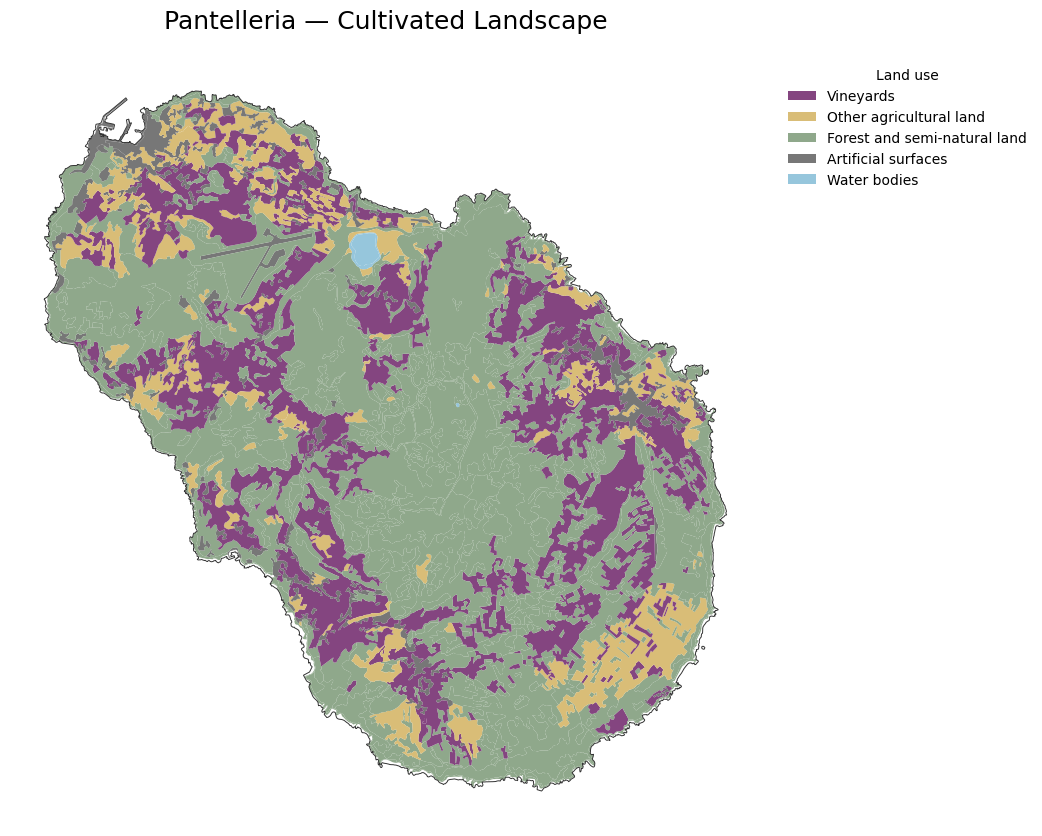

In [42]:
from matplotlib.patches import Patch

palette = {
    "Vineyards": "#844580",
    "Mixed vineyards": "#bd8abb",
    "Other agricultural land": "#d9bd77",
    "Forest and semi-natural land": "#8fa88b",
    "Artificial surfaces": "#777777",
    "Wetlands": "#76b5ac",
    "Water bodies": "#96c6dc",
    "Unclassified": "#dddddd",
}

fig, ax = plt.subplots(figsize=(12, 10))

land_use.plot(
    ax=ax,
    color=land_use["map_category"].map(palette),
    edgecolor="none",
)

pantelleria.to_crs(land_use.crs).boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.7,
)

legend_items = [
    Patch(facecolor=colour, label=category)
    for category, colour in palette.items()
    if category in land_use["map_category"].values
]

ax.legend(
    handles=legend_items,
    title="Land use",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)

ax.set_title("Pantelleria — Cultivated Landscape", fontsize=18, pad=20)
ax.set_aspect("equal")
ax.set_axis_off()

plt.show()

In [43]:
# Match the contours to the land-use coordinate system
contours_map = contours.to_crs(land_use.crs)

# Identify major contour lines
major = contours_map["codice"].astype(str).str.strip().str.upper().eq("H001")

# Draw ordinary contours with thin, subtle lines
contours_map.loc[~major].plot(
    ax=ax,
    color="#444444",
    linewidth=0.2,
    alpha=0.35,
)

# Draw major contours with stronger lines
contours_map.loc[major].plot(
    ax=ax,
    color="#333333",
    linewidth=0.5,
    alpha=0.65,
)

<Axes: title={'center': 'Pantelleria — Cultivated Landscape'}>

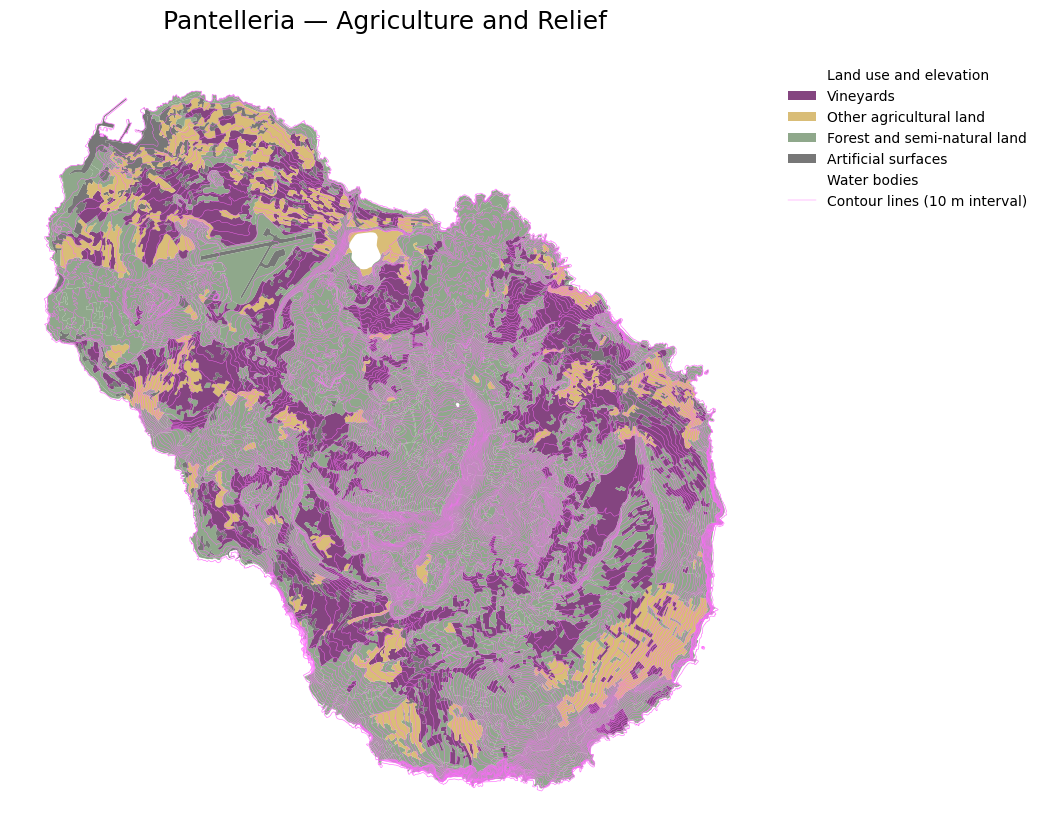

In [51]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

palette = {
    "Vineyards": "#844580",
    "Mixed vineyards": "#bd8abb",
    "Other agricultural land": "#d9bd77",
    "Forest and semi-natural land": "#8fa88b",
    "Artificial surfaces": "#777777",
    "Wetlands": "#76b5ac00",
    "Water bodies": "#96c6dc00",
    "Unclassified": "#dddddd",
}

# Prepare layers in the same coordinate system
contours_map = contours.to_crs(land_use.crs)
island_map = pantelleria.to_crs(land_use.crs)

# Create a new figure
fig, ax = plt.subplots(figsize=(12, 10))

# Draw land-use colours
land_use.plot(
    ax=ax,
    color=land_use["map_category"].map(palette).fillna("#dddddd"),
    edgecolor="none",
    zorder=1,
)

# Draw all contour lines in pink
contours_map.plot(
    ax=ax,
    color="#FF6BFD",
    linewidth=0.30,
    zorder=2,
)

# Draw the island boundary in pink
island_map.boundary.plot(
    ax=ax,
    color="#FF6BFD",
    linewidth=0.45,
    zorder=3,
)

# Create the legend
legend_items = [
    Patch(facecolor=colour, label=category)
    for category, colour in palette.items()
    if category in land_use["map_category"].values
]

legend_items.append(
    Line2D(
        [0],
        [0],
        color="#FF6BFD",
        linewidth=0.30,
        label="Contour lines (10 m interval)",
    )
)

ax.legend(
    handles=legend_items,
    title="Land use and elevation",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)

ax.set_title(
    "Pantelleria — Agriculture and Relief",
    fontsize=18,
    pad=20,
)
ax.set_aspect("equal")
ax.set_axis_off()

plt.show()